# 중간고사 대비 · 데이터 전처리와 모델 학습
기존 모델에서 사용하는 Iris, Pima, Ames, ETTh1, IRB2400 데이터만 사용합니다. Wine은 제외했습니다.
Fashion-MNIST는 포함하지 않습니다. Iris는 이미지 대신 샘플별 특성값을 2×5 막대그래프로 표시합니다.

각 문제는 **문제 설명 셀 1개 + 코드 셀 1개**입니다. 공통 준비 후 위에서부터 풀어 주세요.
선행 문제가 표시된 문제는 앞 문제에서 만든 변수를 사용합니다. 데이터셋마다 변수 앞 이름을 달리했습니다.

CSV 파일을 Drive의 `MyDrive/Colab Notebooks/data/`에 준비하세요.
로컬에서는 각 데이터 문제의 `FILE_PATH`를 실제 CSV 위치로 수정하세요.
`fit`은 훈련에만, 검증은 모델 선택에, 테스트는 최종 평가에만 사용합니다.
정확도 기준을 맞추는 시험이 아니라 전처리·shape·규제·평가 흐름을 연습하는 자료입니다.

**정답과 실제 실행 출력:** QUICK_RUN=True에서 2 epoch로 실행했습니다.
큰 데이터는 먼저 분할한 뒤 훈련 최대 1,024개·검증/테스트 최대 256개만 사용합니다.
저장된 지표는 실행 확인용이며 충분히 학습한 성능이나 기법의 성능 개선 증거가 아닙니다.
전체 학습은 QUICK_RUN=False로 바꿔 처음부터 실행하세요.

실행 환경은 로컬 CPU이며, 데이터 읽기 점검에서만 FILE_PATH를 같은 CSV의 로컬 캐시 경로로 바꿨습니다.


## 공통 준비 1. 라이브러리와 설정


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
    LabelEncoder,
    OneHotEncoder,
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    ConfusionMatrixDisplay,
)
import joblib

# 정답의 저장 출력은 빠른 점검 모드에서 직접 실행한 결과입니다.
# 전체 학습은 False로 바꿔 공통 준비부터 다시 실행하세요.
QUICK_RUN = True
EPOCHS = 2 if QUICK_RUN else 60
SEED = 42
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=4, suppress=True)
SAVE_DIR = Path("midterm_artifacts")
SAVE_DIR.mkdir(exist_ok=True)


def limit_for_quick(Xtr, Xva, Xte, ytr, yva, yte):
    """분할 이후에만 점검용 샘플 수를 줄입니다. 전체 연습에서는 그대로 반환합니다."""
    print("Full train/validation/test:", len(ytr), len(yva), len(yte))
    if QUICK_RUN:
        Xtr, ytr = Xtr[:1024], ytr[:1024]
        Xva, yva = Xva[:256], yva[:256]
        Xte, yte = Xte[:256], yte[:256]
    print("Used train/validation/test:", len(ytr), len(yva), len(yte))
    return Xtr, Xva, Xte, ytr, yva, yte


print("TensorFlow:", tf.__version__, "| Quick run:", QUICK_RUN, "| Epochs:", EPOCHS)


TensorFlow: 2.21.0 | Quick run: True | Epochs: 2


## 공통 준비 2. Google Drive 연결


In [2]:
try:
    from google.colab import drive

    drive.mount("/content/drive")
except ImportError:
    print(
        "Google Colab이 아닙니다. 각 데이터 문제의 FILE_PATH를 로컬 경로로 수정하세요."
    )


Google Colab이 아닙니다. 각 데이터 문제의 FILE_PATH를 로컬 경로로 수정하세요.


## 문제 1. Iris 불러오기와 검증 데이터 분리

**선행:** 공통 준비

1. Drive의 iris3.csv를 읽고 입력 4개와 species를 분리하세요.
2. 클래스 비율을 유지하면서 훈련/검증/테스트를 60/20/20으로 나누세요.
3. 분할 크기와 훈련 클래스별 개수를 출력하세요.


In [3]:
FILE_PATH = "/content/drive/MyDrive/Colab Notebooks/data/iris3.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"데이터 파일을 찾을 수 없습니다: {FILE_PATH}\n"
        "FILE_PATH를 실제 iris3.csv 위치로 수정하세요."
    )

# 각 문제에서 사용할 원본 CSV를 읽습니다.
iris_df = pd.read_csv(FILE_PATH)

iris_X = iris_df.drop(columns="species").to_numpy(dtype="float32")
iris_y = iris_df["species"].to_numpy()

# 테스트 20%를 먼저 분리하고, 나머지에서 검증 데이터를 분리합니다.
iris_X_mid, iris_X_test_raw, iris_y_mid, iris_y_test = train_test_split(
    iris_X, iris_y, test_size=0.2, random_state=SEED, stratify=iris_y
)
iris_X_train_raw, iris_X_val_raw, iris_y_train, iris_y_val = train_test_split(
    iris_X_mid, iris_y_mid, test_size=0.25, random_state=SEED, stratify=iris_y_mid
)
(
    iris_X_train_raw,
    iris_X_val_raw,
    iris_X_test_raw,
    iris_y_train,
    iris_y_val,
    iris_y_test,
) = limit_for_quick(
    iris_X_train_raw,
    iris_X_val_raw,
    iris_X_test_raw,
    iris_y_train,
    iris_y_val,
    iris_y_test,
)

print("Train label counts:", pd.Series(iris_y_train).value_counts().to_dict())
assert len(iris_y_train) == 90 and len(iris_y_val) == 30 and len(iris_y_test) == 30


Full train/validation/test: 90 30 30
Used train/validation/test: 90 30 30
Train label counts: {'Iris-virginica': 30, 'Iris-setosa': 30, 'Iris-versicolor': 30}


## 문제 2. Iris 0~1 정규화와 라벨 인코딩

**선행:** 문제 1

1. MinMaxScaler는 훈련 입력에만 fit하고 검증·테스트에는 transform하세요.
2. species를 정수로 인코딩한 뒤 클래스 3개의 one-hot 정답을 만드세요.
3. 훈련 입력의 최솟값·최댓값과 변환 후 shape를 출력하세요.


In [4]:
# 새 값이 훈련 범위를 벗어나면 변환값도 0~1 밖일 수 있습니다.
iris_scaler = MinMaxScaler()
iris_X_train = iris_scaler.fit_transform(iris_X_train_raw).astype("float32")
iris_X_val = iris_scaler.transform(iris_X_val_raw).astype("float32")
iris_X_test = iris_scaler.transform(iris_X_test_raw).astype("float32")
iris_encoder = LabelEncoder().fit(iris_y_train)
iris_y_train_id = iris_encoder.transform(iris_y_train)
iris_y_val_id = iris_encoder.transform(iris_y_val)
iris_y_test_id = iris_encoder.transform(iris_y_test)
iris_y_train_fit = keras.utils.to_categorical(iris_y_train_id, num_classes=3)
iris_y_val_fit = keras.utils.to_categorical(iris_y_val_id, num_classes=3)
print("Train min/max:", iris_X_train.min(), iris_X_train.max())
print("Input / target shape:", iris_X_train.shape, iris_y_train_fit.shape)
assert iris_X_train.min() >= -1e-6 and iris_X_train.max() <= 1 + 1e-6
assert iris_y_train_fit.shape == (90, 3)


Train min/max: 0.0 1.0000001
Input / target shape: (90, 4) (90, 3)


## 문제 3. 훈련 데이터 앞 10개를 2×5로 시각화

**선행:** 문제 2

1. 정규화한 Iris 훈련 샘플 앞 10개를 2행×5열로 배치하세요.
2. 각 샘플의 4개 특성값은 막대그래프로 그리고 품종을 제목에 표시하세요.


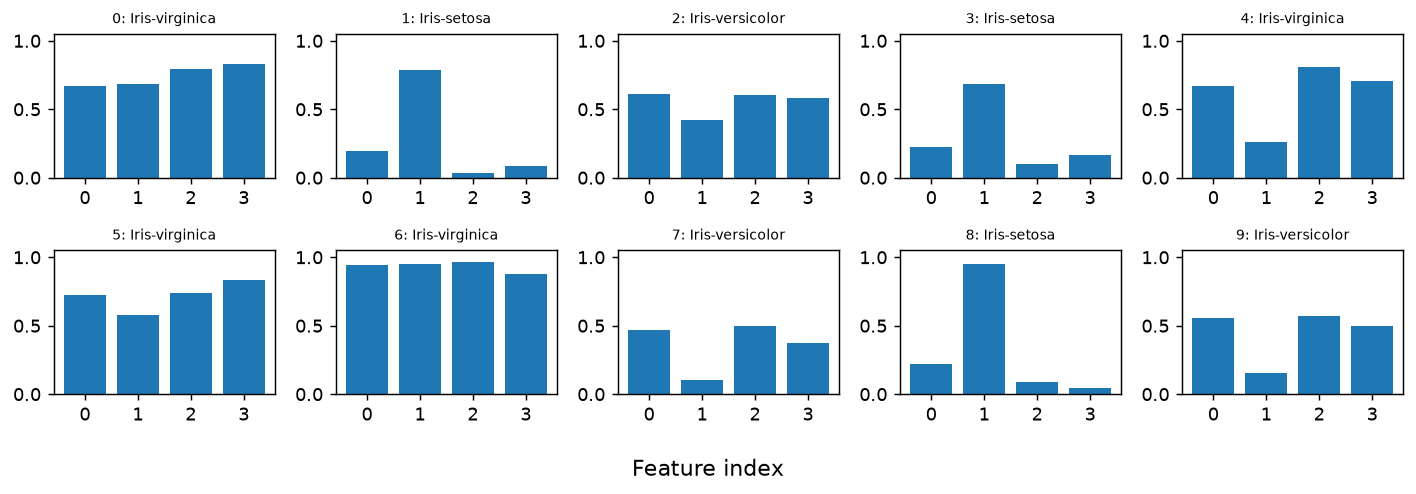

In [5]:
# Iris는 이미지가 아니므로 특성값 4개를 샘플별 막대그래프로 그립니다.
fig, axes = plt.subplots(2, 5, figsize=(11, 3.8))
for i, ax in enumerate(axes.flat):
    ax.bar(range(4), iris_X_train[i])
    ax.set_title(f"{i}: {iris_y_train[i]}", fontsize=8)
    ax.set_xticks(range(4))
    ax.set_ylim(0, 1.05)
fig.supxlabel("Feature index")
fig.tight_layout()
plt.show()
assert len(fig.axes) == 10


## 문제 4. Iris 모델에 weight decay와 과적합 억제 적용

**선행:** 문제 2

1. 4→12→8→3 구조에 ReLU와 softmax를 사용하세요.
2. AdamW(learning_rate=0.001, weight_decay=0.0001)를 적용하세요.
3. Dropout(0.1)과 검증 손실 기준 EarlyStopping을 사용하세요.
4. one-hot 정답에 맞는 손실을 지정하고 검증 데이터와 함께 학습하세요.


In [6]:
keras.utils.set_random_seed(SEED)
# 입력 → 은닉층 → 출력층. 출력 수와 활성화는 정답 형태에 맞춥니다.
iris_model = Sequential(
    [
        Input(shape=(4,)),
        Dense(12, activation="relu"),
        Dropout(0.1),
        Dense(8, activation="relu"),
        Dense(3, activation="softmax"),
    ]
)
# weight decay는 optimizer에, Dropout은 층에 적용합니다.
iris_model.compile(
    optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss="categorical_crossentropy",
)
# 가장 낮은 검증 손실의 가중치를 복원합니다.
iris_early = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
iris_history = iris_model.fit(
    iris_X_train,
    iris_y_train_fit,
    validation_data=(iris_X_val, iris_y_val_fit),
    epochs=EPOCHS,
    batch_size=32,
    callbacks=[iris_early],
    shuffle=True,
    verbose=0,
)
print("Epochs:", len(iris_history.history["loss"]))
print(
    "Last train/validation loss:",
    round(iris_history.history["loss"][-1], 4),
    round(iris_history.history["val_loss"][-1], 4),
)
print("Weight decay:", iris_model.optimizer.weight_decay, "| Dropout:", 0.1)
assert iris_model.optimizer.weight_decay == 0.0001
assert any(isinstance(layer, Dropout) for layer in iris_model.layers)


Epochs: 2
Last train/validation loss: 1.0774 1.0757
Weight decay: 0.0001 | Dropout: 0.1


## 문제 5. Iris 학습 곡선과 최종 평가

**선행:** 문제 4

1. 훈련 손실과 검증 손실을 같은 그래프에 그리세요.
2. 테스트 확률에서 argmax로 라벨을 구하고 정확도와 혼동행렬을 출력하세요.


Test accuracy: 0.3333


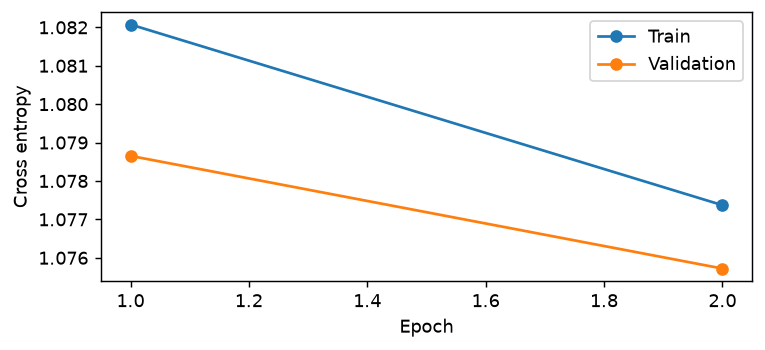

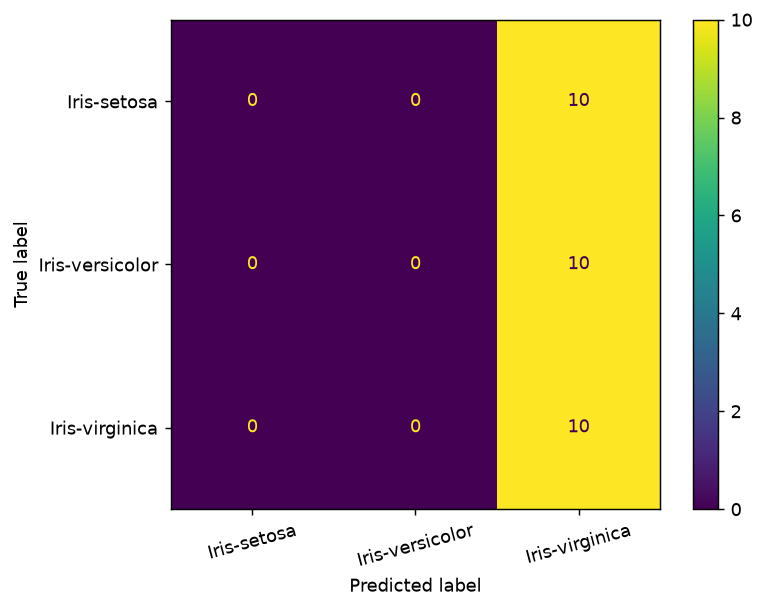

In [7]:
epochs_run = np.arange(1, len(iris_history.history["loss"]) + 1)
plt.figure(figsize=(6, 2.8))
plt.plot(epochs_run, iris_history.history["loss"], marker="o", label="Train")
plt.plot(epochs_run, iris_history.history["val_loss"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Cross entropy")
plt.legend()
plt.tight_layout()
plt.show()
# 테스트는 학습 설정 선택이 끝난 뒤 평가에만 사용합니다.
iris_prob = iris_model.predict(iris_X_test, verbose=0)
iris_pred = iris_prob.argmax(axis=1)
print("Test accuracy:", round(accuracy_score(iris_y_test_id, iris_pred), 4))
ConfusionMatrixDisplay.from_predictions(
    iris_y_test_id, iris_pred, labels=np.arange(3), display_labels=iris_encoder.classes_
)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
assert np.allclose(iris_prob.sum(axis=1), 1, atol=1e-5)


## 문제 6. Pima의 결측값 처리와 표준화

**선행:** 공통 준비

1. Pima CSV의 plasma, pressure, thickness, insulin, bmi에 있는 0을 NaN으로 바꾸세요.
2. pregnant의 0은 유지하고 diabetes를 정답으로 분리하세요.
3. 층화 60/20/20 분할 후 훈련 중앙값으로 대체하고 표준화하세요.


In [8]:
FILE_PATH = "/content/drive/MyDrive/Colab Notebooks/data/pima-indians-diabetes3.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"데이터 파일을 찾을 수 없습니다: {FILE_PATH}\n"
        "FILE_PATH를 실제 pima-indians-diabetes3.csv 위치로 수정하세요."
    )

# 각 문제에서 사용할 원본 CSV를 읽습니다.
pima_df = pd.read_csv(FILE_PATH)

zero_cols = ["plasma", "pressure", "thickness", "insulin", "bmi"]
pregnant_zeros = int((pima_df["pregnant"] == 0).sum())
pima_df[zero_cols] = pima_df[zero_cols].replace(0, np.nan)
assert int((pima_df["pregnant"] == 0).sum()) == pregnant_zeros
pima_X = pima_df.drop(columns="diabetes").to_numpy(dtype="float32")
pima_y = pima_df["diabetes"].to_numpy(dtype="int32")

# 테스트 20%를 먼저 분리하고, 나머지에서 검증 데이터를 분리합니다.
pima_X_mid, pima_X_test_raw, pima_y_mid, pima_y_test = train_test_split(
    pima_X, pima_y, test_size=0.2, random_state=SEED, stratify=pima_y
)
pima_X_train_raw, pima_X_val_raw, pima_y_train, pima_y_val = train_test_split(
    pima_X_mid, pima_y_mid, test_size=0.25, random_state=SEED, stratify=pima_y_mid
)
(
    pima_X_train_raw,
    pima_X_val_raw,
    pima_X_test_raw,
    pima_y_train,
    pima_y_val,
    pima_y_test,
) = limit_for_quick(
    pima_X_train_raw,
    pima_X_val_raw,
    pima_X_test_raw,
    pima_y_train,
    pima_y_val,
    pima_y_test,
)

# Pipeline을 fit하면 중앙값과 평균·표준편차가 모두 훈련에서만 계산됩니다.
pima_prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
pima_X_train = pima_prep.fit_transform(pima_X_train_raw).astype("float32")
pima_X_val = pima_prep.transform(pima_X_val_raw).astype("float32")
pima_X_test = pima_prep.transform(pima_X_test_raw).astype("float32")
pima_y_train_fit, pima_y_val_fit = pima_y_train, pima_y_val
print("Remaining NaN:", int(np.isnan(pima_X_train).sum()))
print("Train feature means:", pima_X_train.mean(axis=0).round(4))
assert np.isfinite(pima_X_train).all() and np.isfinite(pima_X_test).all()


Full train/validation/test: 460 154 154
Used train/validation/test: 460 154 154
Remaining NaN: 0
Train feature means: [-0.  0. -0.  0. -0. -0.  0.  0.]


## 문제 7. Pima 이진 분류 모델과 F1 평가

**선행:** 문제 6

1. 8→16→8→1 구조에서 출력에 sigmoid, 손실에 binary cross entropy를 사용하세요.
2. AdamW와 Dropout 또는 EarlyStopping 등 과적합 억제를 적용하세요.
3. 확률 0.5를 기준으로 테스트 정확도와 F1을 출력하세요.


In [9]:
keras.utils.set_random_seed(SEED)
# 입력 → 은닉층 → 출력층. 출력 수와 활성화는 정답 형태에 맞춥니다.
pima_model = Sequential(
    [
        Input(shape=(8,)),
        Dense(16, activation="relu"),
        Dropout(0.1),
        Dense(8, activation="relu"),
        Dense(1, activation="sigmoid"),
    ]
)
# weight decay는 optimizer에, Dropout은 층에 적용합니다.
pima_model.compile(
    optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss="binary_crossentropy",
)
# 가장 낮은 검증 손실의 가중치를 복원합니다.
pima_early = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
pima_history = pima_model.fit(
    pima_X_train,
    pima_y_train_fit,
    validation_data=(pima_X_val, pima_y_val_fit),
    epochs=EPOCHS,
    batch_size=32,
    callbacks=[pima_early],
    shuffle=True,
    verbose=0,
)
print("Epochs:", len(pima_history.history["loss"]))
print(
    "Last train/validation loss:",
    round(pima_history.history["loss"][-1], 4),
    round(pima_history.history["val_loss"][-1], 4),
)
print("Weight decay:", pima_model.optimizer.weight_decay, "| Dropout:", 0.1)
assert pima_model.optimizer.weight_decay == 0.0001
assert any(isinstance(layer, Dropout) for layer in pima_model.layers)

pima_prob = pima_model.predict(pima_X_test, verbose=0).ravel()
pima_pred = (pima_prob >= 0.5).astype(int)
print("Test accuracy:", round(accuracy_score(pima_y_test, pima_pred), 4))
print("Test F1:", round(f1_score(pima_y_test, pima_pred, zero_division=0), 4))
assert pima_prob.shape == pima_y_test.shape


Epochs: 2
Last train/validation loss: 0.757 0.725
Weight decay: 0.0001 | Dropout: 0.1
Test accuracy: 0.3506
Test F1: 0.5192


## 문제 8. Ames의 수치·범주 전처리와 가격 변환

**선행:** 공통 준비

1. OverallQual, GrLivArea, GarageCars, TotalBsmtSF, Neighborhood로 SalePrice를 예측하도록 준비하세요.
2. 60/20/20 분할 후 수치형은 중앙값 대체·표준화, Neighborhood는 one-hot 인코딩하세요.
3. 새 범주를 무시하도록 설정하고, 정답 가격에는 log1p 후 표준화를 적용하세요.


In [10]:
FILE_PATH = "/content/drive/MyDrive/Colab Notebooks/data/ames_train.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"데이터 파일을 찾을 수 없습니다: {FILE_PATH}\n"
        "FILE_PATH를 실제 ames_train.csv 위치로 수정하세요."
    )

# 각 문제에서 사용할 원본 CSV를 읽습니다.
ames_df = pd.read_csv(FILE_PATH)

ames_numeric = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF"]
ames_categorical = ["Neighborhood"]
ames_X = ames_df[ames_numeric + ames_categorical]
ames_y = ames_df[["SalePrice"]].to_numpy(dtype="float32")

# 테스트 20%를 먼저 분리하고, 나머지에서 검증 데이터를 분리합니다.
ames_X_mid, ames_X_test_raw, ames_y_mid, ames_y_test = train_test_split(
    ames_X, ames_y, test_size=0.2, random_state=SEED
)
ames_X_train_raw, ames_X_val_raw, ames_y_train, ames_y_val = train_test_split(
    ames_X_mid, ames_y_mid, test_size=0.25, random_state=SEED
)
(
    ames_X_train_raw,
    ames_X_val_raw,
    ames_X_test_raw,
    ames_y_train,
    ames_y_val,
    ames_y_test,
) = limit_for_quick(
    ames_X_train_raw,
    ames_X_val_raw,
    ames_X_test_raw,
    ames_y_train,
    ames_y_val,
    ames_y_test,
)

ames_prep = ColumnTransformer(
    [
        (
            "numeric",
            make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
            ames_numeric,
        ),
        (
            "category",
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
            ames_categorical,
        ),
    ]
)
ames_X_train = ames_prep.fit_transform(ames_X_train_raw).astype("float32")
ames_X_val = ames_prep.transform(ames_X_val_raw).astype("float32")
ames_X_test = ames_prep.transform(ames_X_test_raw).astype("float32")
ames_y_scaler = StandardScaler()
ames_y_train_fit = ames_y_scaler.fit_transform(np.log1p(ames_y_train)).astype("float32")
ames_y_val_fit = ames_y_scaler.transform(np.log1p(ames_y_val)).astype("float32")
print("Encoded input shape:", ames_X_train.shape)
print("Target shape:", ames_y_train_fit.shape)
assert np.isfinite(ames_X_train).all() and np.isfinite(ames_X_val).all()


Full train/validation/test: 876 292 292
Used train/validation/test: 876 256 256
Encoded input shape: (876, 28)
Target shape: (876, 1)


## 문제 9. Ames 회귀와 원래 가격 단위의 MAE

**선행:** 문제 8

1. 전처리된 입력→32→16→1의 선형 출력 모델을 MSE로 학습하세요.
2. AdamW와 Dropout·EarlyStopping을 적용하세요.
3. 출력의 표준화와 로그 변환을 역으로 되돌린 뒤 테스트 MAE를 계산하세요.


In [11]:
keras.utils.set_random_seed(SEED)
# 입력 → 은닉층 → 출력층. 출력 수와 활성화는 정답 형태에 맞춥니다.
ames_model = Sequential(
    [
        Input(shape=(ames_X_train.shape[1],)),
        Dense(32, activation="relu"),
        Dropout(0.1),
        Dense(16, activation="relu"),
        Dense(1, activation="linear"),
    ]
)
# weight decay는 optimizer에, Dropout은 층에 적용합니다.
ames_model.compile(
    optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001), loss="mse"
)
# 가장 낮은 검증 손실의 가중치를 복원합니다.
ames_early = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
ames_history = ames_model.fit(
    ames_X_train,
    ames_y_train_fit,
    validation_data=(ames_X_val, ames_y_val_fit),
    epochs=EPOCHS,
    batch_size=32,
    callbacks=[ames_early],
    shuffle=True,
    verbose=0,
)
print("Epochs:", len(ames_history.history["loss"]))
print(
    "Last train/validation loss:",
    round(ames_history.history["loss"][-1], 4),
    round(ames_history.history["val_loss"][-1], 4),
)
print("Weight decay:", ames_model.optimizer.weight_decay, "| Dropout:", 0.1)
assert ames_model.optimizer.weight_decay == 0.0001
assert any(isinstance(layer, Dropout) for layer in ames_model.layers)

ames_pred_scaled = ames_model.predict(ames_X_test, verbose=0)
# 표준화를 먼저 역변환하고, 마지막에 expm1로 로그 변환을 되돌립니다.
ames_pred = np.expm1(ames_y_scaler.inverse_transform(ames_pred_scaled))
print(
    "Test MAE (original price unit):",
    round(mean_absolute_error(ames_y_test, ames_pred), 2),
)
print("First 3 [actual,predicted]:")
print(np.column_stack([ames_y_test[:3], ames_pred[:3]]).round(0))
assert ames_pred.shape == ames_y_test.shape and np.isfinite(ames_pred).all()


Epochs: 2
Last train/validation loss: 0.5348 0.3698
Weight decay: 0.0001 | Dropout: 0.1
Test MAE (original price unit): 32950.41
First 3 [actual,predicted]:
[[154500. 151044.]
 [325000. 212845.]
 [115000. 147492.]]


## 문제 10. ETTh1 시간순 분할과 window 생성

**선행:** 공통 준비

1. 날짜를 변환·정렬하고 OT만 사용하세요. 시간순 70/15/15 경계를 잡으세요.
2. 앞 70% 원시 OT에만 StandardScaler를 fit하세요.
3. 과거 24개→다음 1개 window를 만들고 정답 시점으로 분할하세요.


In [12]:
FILE_PATH = "/content/drive/MyDrive/Colab Notebooks/data/ETTh1.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"데이터 파일을 찾을 수 없습니다: {FILE_PATH}\n"
        "FILE_PATH를 실제 ETTh1.csv 위치로 수정하세요."
    )

# 각 문제에서 사용할 원본 CSV를 읽습니다.
etth_df = pd.read_csv(FILE_PATH)

etth_df["date"] = pd.to_datetime(etth_df["date"])
etth_df = etth_df.sort_values("date").reset_index(drop=True)
etth_raw = etth_df[["OT"]].to_numpy(dtype="float32")
etth_train_end, etth_val_end = int(0.7 * len(etth_raw)), int(0.85 * len(etth_raw))
etth_scaler = StandardScaler().fit(etth_raw[:etth_train_end])
etth_scaled = etth_scaler.transform(etth_raw).ravel().astype("float32")
etth_times = np.arange(24, len(etth_scaled))
etth_X = np.stack([etth_scaled[t - 24 : t] for t in etth_times])
etth_y = etth_scaled[etth_times, None]
etth_train_mask = etth_times < etth_train_end
etth_val_mask = (etth_times >= etth_train_end) & (etth_times < etth_val_end)
etth_test_mask = etth_times >= etth_val_end
etth_X_train, etth_X_val, etth_X_test = (
    etth_X[m] for m in [etth_train_mask, etth_val_mask, etth_test_mask]
)
etth_y_train, etth_y_val, etth_y_test = (
    etth_y[m] for m in [etth_train_mask, etth_val_mask, etth_test_mask]
)
etth_X_train, etth_X_val, etth_X_test, etth_y_train, etth_y_val, etth_y_test = (
    limit_for_quick(
        etth_X_train, etth_X_val, etth_X_test, etth_y_train, etth_y_val, etth_y_test
    )
)
etth_y_train_fit, etth_y_val_fit = etth_y_train, etth_y_val
print("Window input/target shape:", etth_X_train.shape, etth_y_train_fit.shape)
assert etth_X_train.shape[1:] == (24,) and etth_y_train_fit.shape[1:] == (1,)
assert etth_times[etth_train_mask].max() < etth_times[etth_val_mask].min()


Full train/validation/test: 12170 2613 2613
Used train/validation/test: 1024 256 256
Window input/target shape: (1024, 24) (1024, 1)


## 문제 11. ETTh1 학습과 Last Value 기준선 비교

**선행:** 문제 10

1. 24→32→16→1 구조를 MSE로 학습하고 shuffle=False로 설정하세요.
2. 예측을 원래 OT 단위로 복원하고 테스트 MAE를 출력하세요.
3. 마지막 입력값을 예측으로 쓰는 Last Value와 비교하고 앞 100개를 그리세요.


Epochs: 2
Last train/validation loss: 0.2576 2.2695
Weight decay: 0.0001 | Dropout: 0.1
MLP MAE: 11.0617
Last Value MAE: 0.5106


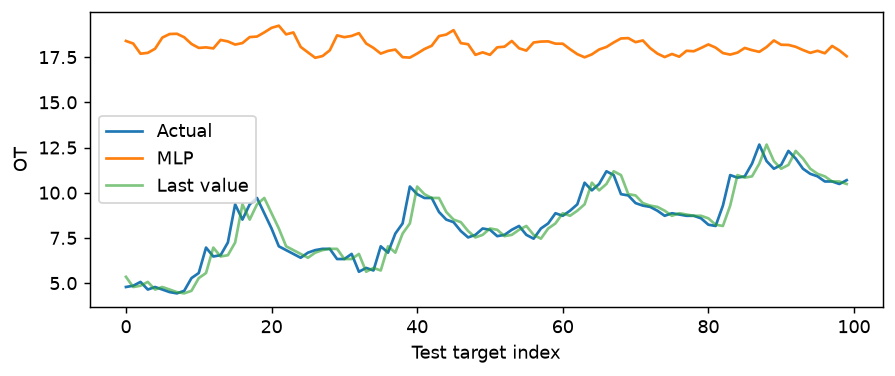

In [13]:
keras.utils.set_random_seed(SEED)
# 입력 → 은닉층 → 출력층. 출력 수와 활성화는 정답 형태에 맞춥니다.
etth_model = Sequential(
    [
        Input(shape=(24,)),
        Dense(32, activation="relu"),
        Dropout(0.1),
        Dense(16, activation="relu"),
        Dense(1, activation="linear"),
    ]
)
# weight decay는 optimizer에, Dropout은 층에 적용합니다.
etth_model.compile(
    optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001), loss="mse"
)
# 가장 낮은 검증 손실의 가중치를 복원합니다.
etth_early = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
etth_history = etth_model.fit(
    etth_X_train,
    etth_y_train_fit,
    validation_data=(etth_X_val, etth_y_val_fit),
    epochs=EPOCHS,
    batch_size=32,
    callbacks=[etth_early],
    shuffle=False,
    verbose=0,
)
print("Epochs:", len(etth_history.history["loss"]))
print(
    "Last train/validation loss:",
    round(etth_history.history["loss"][-1], 4),
    round(etth_history.history["val_loss"][-1], 4),
)
print("Weight decay:", etth_model.optimizer.weight_decay, "| Dropout:", 0.1)
assert etth_model.optimizer.weight_decay == 0.0001
assert any(isinstance(layer, Dropout) for layer in etth_model.layers)

etth_actual = etth_scaler.inverse_transform(etth_y_test)
etth_pred = etth_scaler.inverse_transform(etth_model.predict(etth_X_test, verbose=0))
etth_last = etth_scaler.inverse_transform(etth_X_test[:, -1, None])
print("MLP MAE:", round(mean_absolute_error(etth_actual, etth_pred), 4))
print("Last Value MAE:", round(mean_absolute_error(etth_actual, etth_last), 4))
plt.figure(figsize=(7, 3))
plt.plot(etth_actual[:100], label="Actual")
plt.plot(etth_pred[:100], label="MLP")
plt.plot(etth_last[:100], label="Last value", alpha=0.6)
plt.xlabel("Test target index")
plt.ylabel("OT")
plt.legend()
plt.tight_layout()
plt.show()
assert etth_pred.shape == etth_actual.shape and np.isfinite(etth_pred).all()


## 문제 12. IRB2400 FK: 입력·출력 표준화와 다중 회귀

**선행:** 공통 준비

1. q1_in~q6_in으로 x,y,z,yaw,pitch,roll을 예측하도록 64/16/20으로 분할하세요.
2. 입력과 출력에 각각 StandardScaler를 훈련 기준으로 적용하세요.
3. 6→64→32→6 모델에 AdamW와 과적합 억제를 적용하고 출력별 MAE를 계산하세요.
4. 위치 오차(mm)와 자세 오차(rad)를 구분해 출력하세요.


In [14]:
FILE_PATH = "/content/drive/MyDrive/Colab Notebooks/data/datasetIRB2400.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"데이터 파일을 찾을 수 없습니다: {FILE_PATH}\n"
        "FILE_PATH를 실제 datasetIRB2400.csv 위치로 수정하세요."
    )

# 각 문제에서 사용할 원본 CSV를 읽습니다.
fk_df = pd.read_csv(FILE_PATH)

fk_input_cols = [f"q{i}_in" for i in range(1, 7)]
fk_output_cols = ["x", "y", "z", "yaw", "pitch", "roll"]
fk_X = fk_df[fk_input_cols].to_numpy(dtype="float32")
fk_y = fk_df[fk_output_cols].to_numpy(dtype="float32")

# 테스트 20%를 먼저 분리하고, 나머지에서 검증 데이터를 분리합니다.
fk_X_mid, fk_X_test_raw, fk_y_mid, fk_y_test = train_test_split(
    fk_X, fk_y, test_size=0.2, random_state=SEED
)
fk_X_train_raw, fk_X_val_raw, fk_y_train, fk_y_val = train_test_split(
    fk_X_mid, fk_y_mid, test_size=0.2, random_state=SEED
)
fk_X_train_raw, fk_X_val_raw, fk_X_test_raw, fk_y_train, fk_y_val, fk_y_test = (
    limit_for_quick(
        fk_X_train_raw, fk_X_val_raw, fk_X_test_raw, fk_y_train, fk_y_val, fk_y_test
    )
)

# 입력과 정답은 서로 다른 scaler를 훈련 데이터에만 fit합니다.
fk_x_scaler, fk_y_scaler = StandardScaler(), StandardScaler()
fk_X_train = fk_x_scaler.fit_transform(fk_X_train_raw).astype("float32")
fk_X_val = fk_x_scaler.transform(fk_X_val_raw).astype("float32")
fk_X_test = fk_x_scaler.transform(fk_X_test_raw).astype("float32")
fk_y_train_fit = fk_y_scaler.fit_transform(fk_y_train).astype("float32")
fk_y_val_fit = fk_y_scaler.transform(fk_y_val).astype("float32")
assert fk_X_train.shape[1] == 6 and fk_y_train_fit.shape[1] == 6

keras.utils.set_random_seed(SEED)
# 입력 → 은닉층 → 출력층. 출력 수와 활성화는 정답 형태에 맞춥니다.
fk_model = Sequential(
    [
        Input(shape=(6,)),
        Dense(64, activation="relu"),
        Dropout(0.1),
        Dense(32, activation="relu"),
        Dense(6, activation="linear"),
    ]
)
# weight decay는 optimizer에, Dropout은 층에 적용합니다.
fk_model.compile(optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001), loss="mse")
# 가장 낮은 검증 손실의 가중치를 복원합니다.
fk_early = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
fk_history = fk_model.fit(
    fk_X_train,
    fk_y_train_fit,
    validation_data=(fk_X_val, fk_y_val_fit),
    epochs=EPOCHS,
    batch_size=32,
    callbacks=[fk_early],
    shuffle=True,
    verbose=0,
)
print("Epochs:", len(fk_history.history["loss"]))
print(
    "Last train/validation loss:",
    round(fk_history.history["loss"][-1], 4),
    round(fk_history.history["val_loss"][-1], 4),
)
print("Weight decay:", fk_model.optimizer.weight_decay, "| Dropout:", 0.1)
assert fk_model.optimizer.weight_decay == 0.0001
assert any(isinstance(layer, Dropout) for layer in fk_model.layers)

fk_pred = fk_y_scaler.inverse_transform(fk_model.predict(fk_X_test, verbose=0))
fk_mae = np.abs(fk_pred - fk_y_test).mean(axis=0)
print(
    pd.DataFrame(
        {"output": fk_output_cols, "unit": ["mm"] * 3 + ["rad"] * 3, "MAE": fk_mae}
    )
)
assert fk_pred.shape == fk_y_test.shape and np.isfinite(fk_pred).all()


Full train/validation/test: 192000 48000 60000
Used train/validation/test: 1024 256 256
Epochs: 2
Last train/validation loss: 0.9303 0.9168
Weight decay: 0.0001 | Dropout: 0.1
  output unit         MAE
0      x   mm  403.610870
1      y   mm  332.287476
2      z   mm  380.756561
3    yaw  rad    1.633930
4  pitch  rad    0.529905
5   roll  rad    1.316793


## 문제 13. IRB2400 IK: 관절각 예측과 주기성 평가

**선행:** 공통 준비

1. 입력 pose 6개, 정답 q1_out~q6_out을 선택하고 64/16/20으로 나누세요.
2. 입력·출력을 각각 표준화하고 6→64→32→6 모델을 학습하세요.
3. 역변환 후 일반 MAE와 atan2(sin(오차),cos(오차)) 기반 각도 MAE를 관절별로 출력하세요.


In [15]:
FILE_PATH = "/content/drive/MyDrive/Colab Notebooks/data/datasetIRB2400.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"데이터 파일을 찾을 수 없습니다: {FILE_PATH}\n"
        "FILE_PATH를 실제 datasetIRB2400.csv 위치로 수정하세요."
    )

# 각 문제에서 사용할 원본 CSV를 읽습니다.
ik_df = pd.read_csv(FILE_PATH)

ik_input_cols = ["x", "y", "z", "yaw", "pitch", "roll"]
ik_output_cols = [f"q{i}_out" for i in range(1, 7)]
ik_X = ik_df[ik_input_cols].to_numpy(dtype="float32")
ik_y = ik_df[ik_output_cols].to_numpy(dtype="float32")

# 테스트 20%를 먼저 분리하고, 나머지에서 검증 데이터를 분리합니다.
ik_X_mid, ik_X_test_raw, ik_y_mid, ik_y_test = train_test_split(
    ik_X, ik_y, test_size=0.2, random_state=SEED
)
ik_X_train_raw, ik_X_val_raw, ik_y_train, ik_y_val = train_test_split(
    ik_X_mid, ik_y_mid, test_size=0.2, random_state=SEED
)
ik_X_train_raw, ik_X_val_raw, ik_X_test_raw, ik_y_train, ik_y_val, ik_y_test = (
    limit_for_quick(
        ik_X_train_raw, ik_X_val_raw, ik_X_test_raw, ik_y_train, ik_y_val, ik_y_test
    )
)

# 입력과 정답은 서로 다른 scaler를 훈련 데이터에만 fit합니다.
ik_x_scaler, ik_y_scaler = StandardScaler(), StandardScaler()
ik_X_train = ik_x_scaler.fit_transform(ik_X_train_raw).astype("float32")
ik_X_val = ik_x_scaler.transform(ik_X_val_raw).astype("float32")
ik_X_test = ik_x_scaler.transform(ik_X_test_raw).astype("float32")
ik_y_train_fit = ik_y_scaler.fit_transform(ik_y_train).astype("float32")
ik_y_val_fit = ik_y_scaler.transform(ik_y_val).astype("float32")
assert ik_X_train.shape[1] == 6 and ik_y_train_fit.shape[1] == 6

keras.utils.set_random_seed(SEED)
# 입력 → 은닉층 → 출력층. 출력 수와 활성화는 정답 형태에 맞춥니다.
ik_model = Sequential(
    [
        Input(shape=(6,)),
        Dense(64, activation="relu"),
        Dropout(0.1),
        Dense(32, activation="relu"),
        Dense(6, activation="linear"),
    ]
)
# weight decay는 optimizer에, Dropout은 층에 적용합니다.
ik_model.compile(optimizer=AdamW(learning_rate=0.001, weight_decay=0.0001), loss="mse")
# 가장 낮은 검증 손실의 가중치를 복원합니다.
ik_early = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
ik_history = ik_model.fit(
    ik_X_train,
    ik_y_train_fit,
    validation_data=(ik_X_val, ik_y_val_fit),
    epochs=EPOCHS,
    batch_size=32,
    callbacks=[ik_early],
    shuffle=True,
    verbose=0,
)
print("Epochs:", len(ik_history.history["loss"]))
print(
    "Last train/validation loss:",
    round(ik_history.history["loss"][-1], 4),
    round(ik_history.history["val_loss"][-1], 4),
)
print("Weight decay:", ik_model.optimizer.weight_decay, "| Dropout:", 0.1)
assert ik_model.optimizer.weight_decay == 0.0001
assert any(isinstance(layer, Dropout) for layer in ik_model.layers)

ik_pred = ik_y_scaler.inverse_transform(ik_model.predict(ik_X_test, verbose=0))
ik_delta = ik_pred - ik_y_test
ik_wrapped = np.arctan2(np.sin(ik_delta), np.cos(ik_delta))
print(
    pd.DataFrame(
        {
            "joint": ik_output_cols,
            "unit": "rad",
            "MAE": np.abs(ik_delta).mean(axis=0),
            "circular_MAE": np.abs(ik_wrapped).mean(axis=0),
        }
    )
)
assert ik_pred.shape == ik_y_test.shape and np.isfinite(ik_pred).all()


Full train/validation/test: 192000 48000 60000
Used train/validation/test: 1024 256 256
Epochs: 2
Last train/validation loss: 0.9532 0.9342
Weight decay: 0.0001 | Dropout: 0.1
    joint unit       MAE  circular_MAE
0  q1_out  rad  1.399395      1.392712
1  q2_out  rad  0.713912      0.713912
2  q3_out  rad  0.517197      0.517197
3  q4_out  rad  1.723587      1.669115
4  q5_out  rad  1.049900      1.049900
5  q6_out  rad  3.691182      1.409079


## 문제 14. Iris 모델·전처리 저장과 다시 예측

**선행:** 문제 2, 4

1. 문제 4의 모델을 .keras로 저장하고 scaler와 라벨 인코더를 함께 저장하세요.
2. 원시 테스트 샘플 3개에 저장된 scaler와 재로딩한 모델을 적용하세요.
3. 저장 전후 확률이 같은지 확인하고 예측 품종을 출력하세요.


In [16]:
iris_model.save(SAVE_DIR / "iris.keras")
joblib.dump(
    {"scaler": iris_scaler, "encoder": iris_encoder},
    SAVE_DIR / "iris_preprocessing.joblib",
)
iris_loaded = load_model(SAVE_DIR / "iris.keras")
iris_bundle = joblib.load(SAVE_DIR / "iris_preprocessing.joblib")
# 새 원시 입력에도 반드시 훈련 때 저장한 scaler를 적용합니다.
iris_sample = iris_bundle["scaler"].transform(iris_X_test_raw[:3]).astype("float32")
iris_loaded_prob = iris_loaded.predict(iris_sample, verbose=0)
np.testing.assert_allclose(
    iris_loaded_prob, iris_model.predict(iris_sample, verbose=0), rtol=1e-5, atol=1e-6
)
print(
    "Reloaded predictions:",
    iris_bundle["encoder"].inverse_transform(iris_loaded_prob.argmax(axis=1)),
)
print("Saved: iris.keras, iris_preprocessing.joblib")


Reloaded predictions: ['Iris-virginica' 'Iris-virginica' 'Iris-virginica']
Saved: iris.keras, iris_preprocessing.joblib
